# Lab 02 · Forecasting departures and arrivals (regression)

**Roadmap P4.4 · Unit VI · CO4.** How many trips will leave, and arrive at, a station in a given hour?

**Protocol.** The splits are time-based, never random (ARCHITECTURE §8.2):
- every candidate is trained on **1–24 August** and judged on the **validation week, 25–31 August**;
- each algorithm's best configuration is then refit on all of August and scored on **September**;
- September is only ever reported, never used to choose anything. The champion is the algorithm with the
  best validation MAE.

**Baselines** sit next to every model: the global mean, and the **seasonal naive** forecast (the station's
own mean for that weekday and hour over the previous eight weeks). A model is only useful if it beats the
seasonal naive forecast.

In [1]:
import json

import matplotlib.pyplot as plt
from pyspark.ml import Pipeline
from pyspark.ml.regression import DecisionTreeRegressor, GBTRegressor, LinearRegression, RandomForestRegressor
from pyspark.sql import functions as F

from velograph.common.serving import write_serving
from velograph.common.settings import data_paths
from velograph.lab import metrics
from velograph.lab.features import load_dictionary, load_splits, prep_stages
from velograph.lab.session import lab_session

SEED = 315
spark = lab_session("02-regression")
d = load_dictionary()
s = load_splits(spark)
print("Spark", spark.version, "·", spark.sparkContext.applicationId)
print(
    f"train {s.train.count():,} · validation {s.validation.count():,} · "
    f"fit {s.fit.count():,} · test {s.test.count():,} rows"
)

Spark 3.5.8 · local-1792157071270


train 1,367,376 · validation 401,400 · fit 1,768,776 · test 1,717,896 rows


## 1. Baselines

In [2]:
TARGETS = ["departures", "arrivals"]
NAIVE = {"departures": "prof_dep_mean", "arrivals": "prof_arr_mean"}


def baselines(target):
    train_mean = s.train.agg(F.avg(target)).first()[0]
    fit_mean = s.fit.agg(F.avg(target)).first()[0]
    return {
        "global-mean": {
            "validation": metrics.regression(
                s.validation.withColumn("prediction", F.lit(train_mean)), target
            ),
            "test": metrics.regression(s.test.withColumn("prediction", F.lit(fit_mean)), target),
        },
        "seasonal-naive": {
            "validation": metrics.regression(
                s.validation.withColumn("prediction", F.col(NAIVE[target])), target
            ),
            "test": metrics.regression(s.test.withColumn("prediction", F.col(NAIVE[target])), target),
        },
    }


base = {t: baselines(t) for t in TARGETS}
for t in TARGETS:
    for name, m in base[t].items():
        print(
            f"{t:>10} {name:>15}: validation MAE {m['validation']['mae']:.3f} · "
            f"test MAE {m['test']['mae']:.3f} · test R² {m['test']['r2']:.3f}"
        )

departures     global-mean: validation MAE 3.437 · test MAE 3.525 · test R² -0.000
departures  seasonal-naive: validation MAE 1.485 · test MAE 1.562 · test R² 0.721
  arrivals     global-mean: validation MAE 3.443 · test MAE 3.530 · test R² -0.000
  arrivals  seasonal-naive: validation MAE 1.487 · test MAE 1.566 · test R² 0.724


## 2. Feature preparation

One `Pipeline` per model: StringIndexer for the categorical columns (weekday, archetype, district), then
`VectorAssembler`. Trees read the indices as categories; linear models get one-hot vectors (a district id
is a label, not a quantity). LinearRegression standardises internally, so no scaler is needed.

In [3]:
for stage in prep_stages(d, linear=True):
    print(
        type(stage).__name__, stage.getOutputCols() if stage.hasParam("outputCols") else stage.getOutputCol()
    )

StringIndexer ['dow_idx', 'archetype_idx', 'community_idx']
OneHotEncoder ['dow_ohe', 'archetype_ohe', 'community_ohe']
VectorAssembler features


## 3. Candidates, tuned on departures

A small grid per algorithm. Each configuration is trained on 1–24 August and scored on the validation week.
Arrivals reuse each algorithm's best departures configuration: the two targets share every feature and the
same daily rhythm, and tuning twice would double the cost for little gain.

Every model is judged on MAE, but squared-error training aims at the *mean*. For counts that are mostly
zero, the MAE-optimal forecast is the *median*, which is lower. Gradient-boosted trees can train on
absolute loss directly, so their grid includes `lossType = absolute`.

In [4]:
# Trees grow level by level, one pass over the data per level. A larger aggregation budget (maxMemoryInMB)
# fits more nodes into each pass, and cached node ids spare re-walking every tree for every row.
TREES = {"minInstancesPerNode": 20, "maxMemoryInMB": 1024, "cacheNodeIds": True, "seed": SEED}
ESTIMATORS = {
    "linear-regression": (True, LinearRegression, {"maxIter": 50}),
    "decision-tree": (False, DecisionTreeRegressor, TREES),
    "random-forest": (False, RandomForestRegressor, {**TREES, "subsamplingRate": 0.5}),
    "gbt": (False, GBTRegressor, {**TREES, "stepSize": 0.1, "subsamplingRate": 0.5}),
}
GRID = {
    "linear-regression": [
        {"regParam": 0.01, "elasticNetParam": 0.0},
        {"regParam": 0.01, "elasticNetParam": 0.5},
        {"regParam": 0.1, "elasticNetParam": 0.5},
    ],
    "decision-tree": [{"maxDepth": 8}, {"maxDepth": 12}],
    "random-forest": [{"numTrees": 30, "maxDepth": 10}, {"numTrees": 30, "maxDepth": 12}],
    "gbt": [
        {"maxIter": 40, "maxDepth": 5},
        {"maxIter": 40, "maxDepth": 7},
        {"maxIter": 60, "maxDepth": 7, "lossType": "absolute"},
    ],
}


def pipeline(algo, params, target, drop_groups=()):
    linear, estimator, fixed = ESTIMATORS[algo]
    model = estimator(featuresCol="features", labelCol=target, **fixed, **params)
    return Pipeline(stages=[*prep_stages(d, linear=linear, drop_groups=drop_groups), model])


tuning = {algo: [] for algo in GRID}
for algo, grid in GRID.items():
    for params in grid:
        fitted = pipeline(algo, params, "departures").fit(s.train)
        m = metrics.regression(fitted.transform(s.validation), "departures")
        tuning[algo].append({"params": params, "validation": m})
        print(f"{algo:>18} {params}: validation MAE {m['mae']:.4f} · R² {m['r2']:.4f}")
chosen = {algo: min(runs, key=lambda r: r["validation"]["mae"])["params"] for algo, runs in tuning.items()}
print(chosen)

 linear-regression {'regParam': 0.01, 'elasticNetParam': 0.0}: validation MAE 1.5560 · R² 0.7504


 linear-regression {'regParam': 0.01, 'elasticNetParam': 0.5}: validation MAE 1.5514 · R² 0.7506


 linear-regression {'regParam': 0.1, 'elasticNetParam': 0.5}: validation MAE 1.5316 · R² 0.7512


     decision-tree {'maxDepth': 8}: validation MAE 1.4895 · R² 0.7125


     decision-tree {'maxDepth': 12}: validation MAE 1.4698 · R² 0.7186


...

     random-forest {'numTrees': 30, 'maxDepth': 12}: validation MAE 1.4214 · R² 0.7582


               gbt {'maxIter': 40, 'maxDepth': 5}: validation MAE 1.4650 · R² 0.7427


               gbt {'maxIter': 40, 'maxDepth': 7}: validation MAE 1.4561 · R² 0.7371


               gbt {'maxIter': 60, 'maxDepth': 7, 'lossType': 'absolute'}: validation MAE 1.4287 · R² 0.7099


{'linear-regression': {'regParam': 0.1, 'elasticNetParam': 0.5},
 'decision-tree': {'maxDepth': 12},
 'random-forest': {'numTrees': 30, 'maxDepth': 12},
 'gbt': {'maxIter': 60, 'maxDepth': 7, 'lossType': 'absolute'}}


## 4. The leaderboard

For each target, every algorithm's chosen configuration is scored on the validation week (trained on
1–24 August) to pick the champion, then refit on all of August and scored on September.

In [5]:
results = {}
predictions = {}
for target in TARGETS:
    rows = []
    for algo, params in chosen.items():
        if target == "departures":  # the same fit as in the tuning run: reuse its score
            validation = next(r["validation"] for r in tuning[algo] if r["params"] == params)
        else:
            on_train = pipeline(algo, params, target).fit(s.train)
            validation = metrics.regression(on_train.transform(s.validation), target)
        final = pipeline(algo, params, target).fit(s.fit)
        scored = final.transform(s.test)
        test = metrics.regression(scored, target)
        predictions[(target, algo)] = (final, scored)
        rows.append({"model": algo, "params": params, "validation": validation, "test": test})
        print(
            f"{target:>10} {algo:>18}: validation MAE {validation['mae']:.4f} · test MAE {test['mae']:.4f} · "
            f"test RMSE {test['rmse']:.3f} · test R² {test['r2']:.4f}"
        )
    champion = min(rows, key=lambda r: r["validation"]["mae"])["model"]
    naive = base[target]["seasonal-naive"]["test"]["mae"]
    best = next(r for r in rows if r["model"] == champion)["test"]["mae"]
    results[target] = {
        "leaderboard": rows,
        "champion": champion,
        "improvementVsNaive": round((naive - best) / naive * 100, 2),
    }
    print(
        f"→ {target} champion: {champion}; test MAE {best:.4f} vs seasonal naive {naive:.4f} "
        f"({results[target]['improvementVsNaive']:+.1f} %)"
    )

departures  linear-regression: validation MAE 1.5316 · test MAE 1.5919 · test RMSE 3.085 · test R² 0.7283


departures      decision-tree: validation MAE 1.4698 · test MAE 1.5227 · test RMSE 3.188 · test R² 0.7099


departures      random-forest: validation MAE 1.4214 · test MAE 1.4595 · test RMSE 2.987 · test R² 0.7454


departures                gbt: validation MAE 1.4287 · test MAE 1.4697 · test RMSE 3.217 · test R² 0.7046
→ departures champion: random-forest; test MAE 1.4595 vs seasonal naive 1.5620 (+6.6 %)


  arrivals  linear-regression: validation MAE 1.5320 · test MAE 1.5910 · test RMSE 3.081 · test R² 0.7323


  arrivals      decision-tree: validation MAE 1.4775 · test MAE 1.5638 · test RMSE 3.363 · test R² 0.6810


  arrivals      random-forest: validation MAE 1.4322 · test MAE 1.4740 · test RMSE 3.028 · test R² 0.7413


  arrivals                gbt: validation MAE 1.4307 · test MAE 1.4674 · test RMSE 3.230 · test R² 0.7057
→ arrivals champion: gbt; test MAE 1.4674 vs seasonal naive 1.5655 (+6.3 %)


**Reading the leaderboard.** The seasonal naive forecast is a strong baseline: it already knows each
station's weekly rhythm from the eight weeks before. What the models add is the part of an hour that habit
does not explain: weather, holidays, and how similar stations behave. With no same-day signal, that part
is small. The previous hour's flow, which the live GBFS feed provides, would be the next feature to add.

## 5. Where the champion errs

The error by hour of day and by station archetype, against the seasonal naive forecast; the residuals; and
a calibration check: for every actual count, the mean of what the champion predicted.

In [6]:
archetypes = json.loads((data_paths().serving / "archetypes.json").read_text(encoding="utf-8"))["data"][
    "archetypes"
]
archetype_names = {a["id"]: a["name"] for a in archetypes}
archetype_names[-1] = "no profile"


def analysis(target):
    final, scored = predictions[(target, results[target]["champion"])]
    scored = scored.persist()
    err = F.abs(F.col("prediction") - F.col(target))
    naive_err = F.abs(F.col(NAIVE[target]) - F.col(target))
    by_hour = [
        {"hour": r["hour"], "champion": round(r["c"], 4), "naive": round(r["n"], 4)}
        for r in scored.groupBy("hour")
        .agg(F.avg(err).alias("c"), F.avg(naive_err).alias("n"))
        .orderBy("hour")
        .collect()
    ]
    by_archetype = [
        {
            "archetype": r["archetype"],
            "name": archetype_names.get(r["archetype"], str(r["archetype"])),
            "champion": round(r["c"], 4),
            "naive": round(r["n"], 4),
            "rows": r["rows"],
        }
        for r in scored.groupBy("archetype")
        .agg(F.avg(err).alias("c"), F.avg(naive_err).alias("n"), F.count(F.lit(1)).alias("rows"))
        .orderBy("archetype")
        .collect()
    ]
    residual = F.greatest(F.lit(-10), F.least(F.lit(10), F.round(F.col("prediction") - F.col(target)))).cast(
        "int"
    )
    total = scored.count()
    residuals = [
        {"bin": r["bin"], "share": round(r["count"] / total, 5)}
        for r in scored.groupBy(residual.alias("bin")).count().orderBy("bin").collect()
    ]
    actual = F.least(F.col(target), F.lit(30)).cast("int")
    calibration = [
        {"actual": r["actual"], "meanPrediction": round(r["p"], 4), "rows": r["rows"]}
        for r in scored.groupBy(actual.alias("actual"))
        .agg(F.avg("prediction").alias("p"), F.count(F.lit(1)).alias("rows"))
        .orderBy("actual")
        .collect()
    ]
    model = final.stages[-1]
    importances = []
    if hasattr(model, "featureImportances"):
        names = final.stages[-2].getInputCols()
        importances = sorted(
            (
                {"feature": n.removesuffix("_idx"), "importance": round(float(v), 5)}
                for n, v in zip(names, model.featureImportances.toArray(), strict=True)
            ),
            key=lambda r: -r["importance"],
        )
    return {
        "byHour": by_hour,
        "byArchetype": by_archetype,
        "residuals": residuals,
        "calibration": calibration,
        "importances": importances,
    }


for target in TARGETS:
    results[target].update(analysis(target))
    results[target]["baselines"] = base[target]
    print(
        target, "top features:", [(i["feature"], i["importance"]) for i in results[target]["importances"][:8]]
    )

departures top features: [('prof_dep_mean', 0.36256), ('prof_arr_mean', 0.22972), ('prof_dep_std', 0.17349), ('prof_arr_std', 0.05271), ('out_strength', 0.02554), ('in_strength', 0.02144), ('pagerank_w', 0.0189), ('humidity_pct', 0.01725)]


arrivals top features: [('prof_arr_mean', 0.81789), ('in_strength', 0.02412), ('out_strength', 0.02118), ('hour_sin', 0.02096), ('dow', 0.0151), ('hour', 0.01494), ('prof_dep_mean', 0.01447), ('hour_cos', 0.01249)]


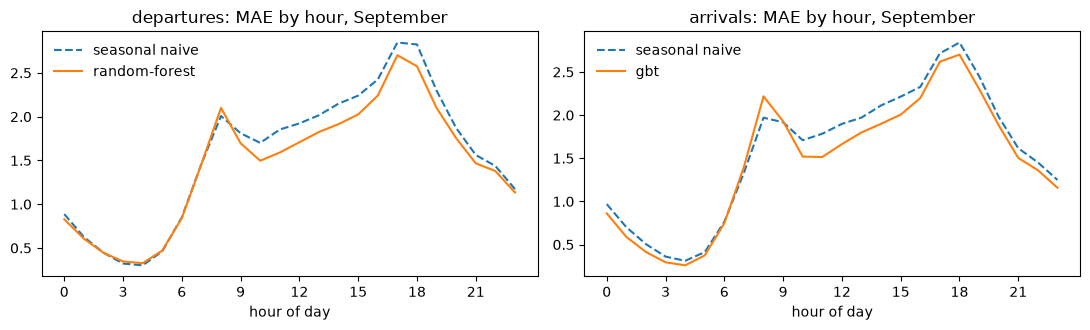

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, target in zip(axes, TARGETS, strict=True):
    hours = results[target]["byHour"]
    ax.plot([h["hour"] for h in hours], [h["naive"] for h in hours], "--", label="seasonal naive")
    ax.plot([h["hour"] for h in hours], [h["champion"] for h in hours], label=results[target]["champion"])
    ax.set_title(f"{target}: MAE by hour, September")
    ax.set_xlabel("hour of day")
    ax.set_xticks(range(0, 24, 3))
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [8]:
path = write_serving(
    data_paths().serving / "ml-regression.json",
    "ml-regression",
    "lab-02-regression",
    {
        "protocol": {
            "train": {"from": d.report["windows"][0]["rows"]["from"], "to": "2026-08-24"},
            "validation": d.report["validation"],
            "test": d.report["windows"][1]["rows"],
            "selection": "lowest validation MAE; September is reported only",
            "tunedOn": "departures",
        },
        "grid": GRID,
        "tuning": tuning,
        "fixedParams": {algo: fixed for algo, (_, _, fixed) in ESTIMATORS.items()},
        "targets": results,
    },
    rows=s.test.count(),
    source={"from": d.report["windows"][0]["profile"]["from"], "to": d.report["windows"][1]["rows"]["to"]},
)
print("wrote", path)

wrote C:\Users\Sayan\Desktop\int315\data\serving\ml-regression.json


In [9]:
spark.stop()